# Adaptive Exam Preparation System ML Project



### **Dataset**
[ASSISTments 2009–2010 Skill Builder](https://sites.google.com/site/assistmentsdata/home/2009-2010-assistment-data/skill-builder-data-2009-2010)




## **0 - Imports & Configuration**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import os

RAW_FILE           = "../data/raw/skill_builder_data_corrected_collapsed.csv"
OUTPUT_DIR         = "../data/processed"                                  # where to save output CSVs
FIGURES_DIR        = "../outputs/figures"                            # where to save plot PNGs

TOPICS_TO_KEEP     = 7     # keep the N most frequent topics
MIN_Q_PER_STUDENT  = 10    # drop students with fewer questions than this
MIN_STUDENTS_PER_Q = 30    # drop questions attempted by fewer students than this
TEST_RATIO         = 0.20  # fraction of students going to the test set
RANDOM_SEED        = 42

os.makedirs(FIGURES_DIR, exist_ok=True)
np.random.seed(RANDOM_SEED)
print("  Libraries loaded and configuration set.")
print(f"    Topics to keep      : {TOPICS_TO_KEEP}")
print(f"    Min questions/student: {MIN_Q_PER_STUDENT}")
print(f"    Min students/question: {MIN_STUDENTS_PER_Q}")
print(f"    Test ratio           : {TEST_RATIO}")

  Libraries loaded and configuration set.
    Topics to keep      : 7
    Min questions/student: 10
    Min students/question: 30
    Test ratio           : 0.2



## **1 - Load Raw Data**

We load the ASSISTments CSV and keep only the 7 columns we need. Everything else is dropped immediately to reduce memory usage.

In [2]:
print("Loading raw data...")

df_raw = pd.read_csv(RAW_FILE, encoding="latin-1", low_memory=False)

print(f"Raw shape : {df_raw.shape}")
print(f"Columns   : {list(df_raw.columns)}")
df_raw.head(3)

Loading raw data...
Raw shape : (346860, 31)
Columns   : ['Unnamed: 0', 'order_id', 'assignment_id', 'user_id', 'assistment_id', 'problem_id', 'original', 'correct', 'attempt_count', 'ms_first_response', 'tutor_mode', 'answer_type', 'sequence_id', 'student_class_id', 'position', 'type', 'base_sequence_id', 'skill_id', 'skill_name', 'teacher_id', 'school_id', 'hint_count', 'hint_total', 'overlap_time', 'template_id', 'answer_id', 'answer_text', 'first_action', 'bottom_hint', 'opportunity', 'opportunity_original']


,Unnamed: 0,order_id,assignment_id,user_id,assistment_id,problem_id,original,correct,attempt_count,ms_first_response,...,hint_count,hint_total,overlap_time,template_id,answer_id,answer_text,first_action,bottom_hint,opportunity,opportunity_original
0,1,33022537,277618,64525,33139,51424,1,1,1,32454,...,0,3,32454,30799,NaN,26,0,NaN,1,1.0
1,2,33022709,277618,64525,33150,51435,1,1,1,4922,...,0,3,4922,30799,NaN,55,0,NaN,2,2.0
2,3,35450204,220674,70363,33159,51444,1,0,2,25390,...,0,3,42000,30799,NaN,88,0,NaN,1,1.0


In [3]:
# Keep only the columns we need
NEEDED_COLS = ["user_id", "problem_id", "correct",
               "skill_name", "ms_first_response",
               "hint_count", "attempt_count"]

available = [c for c in NEEDED_COLS if c in df_raw.columns]
missing   = [c for c in NEEDED_COLS if c not in df_raw.columns]

if missing:
    print(f" These columns are missing from the file: {missing}")
    print("   They will be skipped — the pipeline still works.")

df = df_raw[available].copy()

#  Coerce types
df["correct"]           = pd.to_numeric(df["correct"],           errors="coerce")
df["ms_first_response"] = pd.to_numeric(df["ms_first_response"], errors="coerce")

if "hint_count"    in df.columns: df["hint_count"]    = pd.to_numeric(df["hint_count"],    errors="coerce").fillna(0)
if "attempt_count" in df.columns: df["attempt_count"] = pd.to_numeric(df["attempt_count"], errors="coerce").fillna(1)

# Drop rows missing core fields
before = len(df)
df = df.dropna(subset=["user_id", "problem_id", "correct", "skill_name"])
df["correct"] = df["correct"].astype(int)
after = len(df)

print(f"\n Kept {len(available)}/{len(NEEDED_COLS)} columns")
print(f"   Dropped {before - after} rows with missing core values")
print(f"   Shape after clean: {df.shape}")
df.head()


 Kept 7/7 columns
   Dropped 72270 rows with missing core values
   Shape after clean: (274590, 7)


,user_id,problem_id,correct,skill_name,ms_first_response,hint_count,attempt_count
0,64525,51424,1,Box and Whisker,32454,0,1
1,64525,51435,1,Box and Whisker,4922,0,1
2,70363,51444,0,Box and Whisker,25390,0,2
3,70363,51395,1,Box and Whisker,4859,0,1
4,70363,51481,0,Box and Whisker,19813,3,14


## **2 - Filter Topics**

We keep only the **top N most frequent topics** (by row count). More data per topic means the model trains better — rare topics produce unreliable predictions.

In [4]:
topic_counts = df["skill_name"].value_counts()
print(f"Total unique topics in dataset: {len(topic_counts)}\n")
print("Top 15 topics by row count:")
print(topic_counts.head(15).to_string())

Total unique topics in dataset: 101

Top 15 topics by row count:
skill_name
Equation Solving Two or Fewer Steps         24253
Conversion of Fraction Decimals Percents    18742
Addition and Subtraction Integers           12741
Addition and Subtraction Fractions          11334
Equation Solving More Than Two Steps         8115
Proportion                                   8068
Subtraction Whole Numbers                    7669
Ordering Positive Decimals                   7317
Multiplication and Division Integers         7058
Table                                        6834
Pythagorean Theorem                          6611
Probability of a Single Event                6557
Circle Graph                                 6208
Ordering Fractions                           6117
Finding Percents                             6109


In [5]:
top_topics = topic_counts.head(TOPICS_TO_KEEP).index.tolist()
df = df[df["skill_name"].isin(top_topics)].copy()

print(f"Kept {TOPICS_TO_KEEP} topics:")
for t in top_topics:
    print(f"   • {t}")
print(f"\nShape after topic filter: {df.shape}")

Kept 7 topics:
   • Equation Solving Two or Fewer Steps
   • Conversion of Fraction Decimals Percents
   • Addition and Subtraction Integers
   • Addition and Subtraction Fractions
   • Equation Solving More Than Two Steps
   • Proportion
   • Subtraction Whole Numbers

Shape after topic filter: (90922, 7)


## **3 - Filter Sparse Students & Questions**

We iteratively remove:
- **Students** who answered fewer than `MIN_Q_PER_STUDENT` questions (not enough signal to model their knowledge)
- **Questions** attempted by fewer than `MIN_STUDENTS_PER_Q` students (not enough signal to compute reliable difficulty)

We loop until the dataset is stable (removing one group can make the other sparse again).

In [6]:
prev_shape = None
iteration  = 0

while df.shape != prev_shape:
    prev_shape = df.shape
    iteration += 1

    # Drop sparse students
    student_q_count  = df.groupby("user_id")["problem_id"].count()
    valid_students   = student_q_count[student_q_count >= MIN_Q_PER_STUDENT].index
    df = df[df["user_id"].isin(valid_students)]

    # Drop sparse questions
    question_s_count = df.groupby("problem_id")["user_id"].nunique()
    valid_questions  = question_s_count[question_s_count >= MIN_STUDENTS_PER_Q].index
    df = df[df["problem_id"].isin(valid_questions)]

    print(f"  Iteration {iteration}: {len(df):,} rows | "
          f"{df['user_id'].nunique():,} students | "
          f"{df['problem_id'].nunique():,} questions")

df = df.copy()  # defragment
print(f"\n  Final shape: {df.shape}")

  Iteration 1: 57,441 rows | 1,859 students | 1,050 questions
  Iteration 2: 53,708 rows | 1,489 students | 985 questions
  Iteration 3: 52,638 rows | 1,434 students | 963 questions
  Iteration 4: 52,392 rows | 1,419 students | 959 questions
  Iteration 5: 52,345 rows | 1,417 students | 958 questions
  Iteration 6: 52,345 rows | 1,417 students | 958 questions

  Final shape: (52345, 7)



## **4 - Compute Question Difficulty**

$$\text{difficulty} = 1 - \frac{\text{total correct answers}}{\text{total attempts}}$$

A question where **80% of students fail** -> difficulty = **0.80** (hard)  
A question where **80% of students succeed** -> difficulty = **0.20** (easy)

In [7]:
# Success rate per question
success_rate = df.groupby("problem_id")["correct"].mean()

# Flip: difficulty = 1 - success rate
difficulty_map = (1 - success_rate).clip(0.0, 1.0)

df["difficulty"] = df["problem_id"].map(difficulty_map)

# Label difficulty into buckets (useful for debugging/display)
df["difficulty_label"] = pd.cut(
    df["difficulty"],
    bins=[0, 0.33, 0.67, 1.0],
    labels=["easy", "medium", "hard"],
    include_lowest=True
)

print("  Difficulty computed and added as column.")
print(f"   Range  : [{df['difficulty'].min():.3f}, {df['difficulty'].max():.3f}]")
print(f"   Mean   : {df['difficulty'].mean():.3f}")
print(f"   Std    : {df['difficulty'].std():.3f}")
print("\nDifficulty bucket distribution (per row):")
print(df["difficulty_label"].value_counts())

  Difficulty computed and added as column.
   Range  : [0.000, 0.839]
   Mean   : 0.373
   Std    : 0.155

Difficulty bucket distribution (per row):
difficulty_label
medium    30449
easy      20389
hard       1507
Name: count, dtype: int64



## **5 - Encode Topic Names as Integers**

Machine learning models need numbers, not strings. We sort topic names alphabetically and assign 0, 1, 2, ...

In [8]:
topic_map = {name: idx for idx, name in enumerate(sorted(top_topics))}
df["topic_id"] = df["skill_name"].map(topic_map)

print("Topic encoding:")
for name, idx in topic_map.items():
    count = (df["topic_id"] == idx).sum()
    print(f"   {idx}  ->  {name}  ({count:,} rows)")

Topic encoding:
   0  ->  Addition and Subtraction Fractions  (5,674 rows)
   1  ->  Addition and Subtraction Integers  (9,782 rows)
   2  ->  Conversion of Fraction Decimals Percents  (15,410 rows)
   3  ->  Equation Solving More Than Two Steps  (4,232 rows)
   4  ->  Equation Solving Two or Fewer Steps  (8,841 rows)
   5  ->  Proportion  (3,239 rows)
   6  ->  Subtraction Whole Numbers  (5,167 rows)


## **6 - Normalize Response Time**

We apply **z-score normalization**: subtract the mean and divide by the standard deviation.

$$\text{response\_time\_norm} = \frac{t - \mu}{\sigma}$$

After normalization: mean ≈ 0, std ≈ 1. Missing values are filled with 0 (= the population mean).

In [9]:
rt      = df["ms_first_response"].copy()
mean_rt = rt.mean()
std_rt  = rt.std()

print(f"Response time — mean: {mean_rt:,.1f} ms | std: {std_rt:,.1f} ms")
print(f"Missing values: {rt.isna().sum():,}")

if std_rt > 0:
    df["response_time_norm"] = ((rt - mean_rt) / std_rt).fillna(0.0)
else:
    df["response_time_norm"] = 0.0

print(f"\nAfter normalization — mean: {df['response_time_norm'].mean():.4f} | "
      f"std: {df['response_time_norm'].std():.4f}")

Response time — mean: 44,195.9 ms | std: 330,077.0 ms
Missing values: 0

After normalization — mean: 0.0000 | std: 1.0000



## **7 - Train / Test Split**

We split **at the student level** — not row level. If we split rows randomly, the same student could appear in both train and test, which would be data leakage and give unrealistically high accuracy.

In [10]:
all_students = np.array(sorted(df["user_id"].unique()))
rng = np.random.default_rng(RANDOM_SEED)
rng.shuffle(all_students)

n_test         = int(len(all_students) * TEST_RATIO)
test_students  = all_students[:n_test]
train_students = all_students[n_test:]

train_df = df[df["user_id"].isin(train_students)].copy()
test_df  = df[df["user_id"].isin(test_students)].copy()

print("Split complete")
print(f"   Train : {train_df['user_id'].nunique():,} students | {len(train_df):,} rows")
print(f"   Test  : {test_df['user_id'].nunique():,}  students  | {len(test_df):,}  rows")
print(f"   Overlap check (should be 0): {set(train_students) & set(test_students)}")

Split complete
   Train : 1,134 students | 41,700 rows
   Test  : 283  students  | 10,645  rows
   Overlap check (should be 0): set()


## **8 - Build Question Metadata**

One row per unique question. This is the file Alaa needs to build the question pool for the quiz engine.

In [11]:
meta_df = (
    df.groupby("problem_id")
      .agg(
          difficulty = ("difficulty", "first"),
          topic_id   = ("topic_id",   "first"),
          skill_name = ("skill_name", "first"),
          n_attempts = ("correct",    "count"),
          success_rate = ("correct",  "mean"),
      )
      .reset_index()
)

print(f"Question metadata built: {len(meta_df):,} questions")
print("\nSample:")
meta_df.head(10)

Question metadata built: 958 questions

Sample:


,problem_id,difficulty,topic_id,skill_name,n_attempts,success_rate
0,49292,0.186992,6,Subtraction Whole Numbers,123,0.813008
1,49295,0.198198,6,Subtraction Whole Numbers,111,0.801802
2,49298,0.312500,6,Subtraction Whole Numbers,96,0.687500
3,49301,0.325203,6,Subtraction Whole Numbers,123,0.674797
4,49302,0.564103,6,Subtraction Whole Numbers,39,0.435897
5,49303,0.675676,6,Subtraction Whole Numbers,37,0.324324
6,49304,0.327103,6,Subtraction Whole Numbers,107,0.672897
7,49305,0.657143,6,Subtraction Whole Numbers,35,0.342857
8,49306,0.529412,6,Subtraction Whole Numbers,34,0.470588
9,49307,0.273504,6,Subtraction Whole Numbers,117,0.726496


## **9 - Visualizations**

### Plot 1 — Histogram of Question Difficulty

Shows how hard the questions in our dataset are. We expect a distribution spread across [0, 1] with most questions in the medium range.

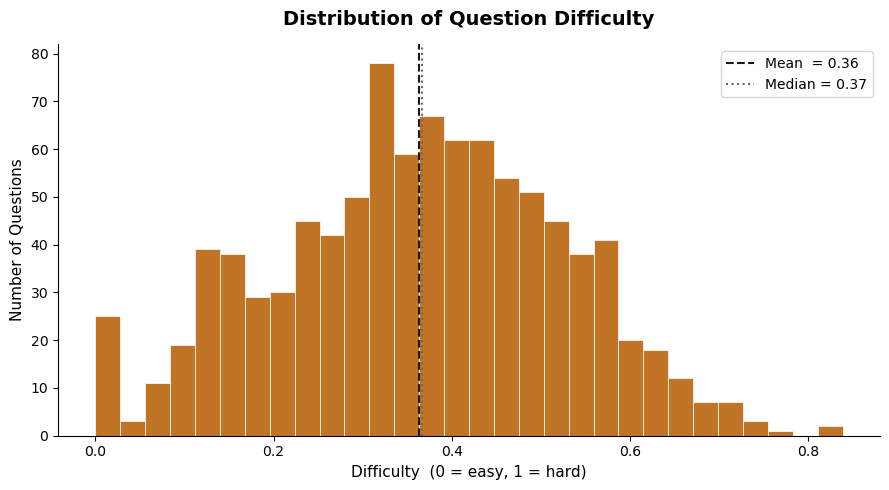

Caption: Each bar shows the number of questions in that difficulty range.
Difficulty = 1 − (average correct rate). Hard questions sit near 1.0, easy near 0.


In [12]:
q_difficulty = meta_df["difficulty"]

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(q_difficulty, bins=30, color="#b85c00", edgecolor="white",
        linewidth=0.6, alpha=0.85)

ax.axvline(q_difficulty.mean(), color="#1a1917", linestyle="--", linewidth=1.5,
           label=f"Mean  = {q_difficulty.mean():.2f}")
ax.axvline(q_difficulty.median(), color="#6b6760", linestyle=":", linewidth=1.5,
           label=f"Median = {q_difficulty.median():.2f}")

ax.set_title("Distribution of Question Difficulty", fontsize=14, fontweight="bold", pad=14)
ax.set_xlabel("Difficulty  (0 = easy, 1 = hard)", fontsize=11)
ax.set_ylabel("Number of Questions", fontsize=11)
ax.legend(fontsize=10)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "plot1_difficulty_distribution.png"), dpi=150, bbox_inches="tight")
plt.show()

print("Caption: Each bar shows the number of questions in that difficulty range.")
print("Difficulty = 1 − (average correct rate). Hard questions sit near 1.0, easy near 0.")

### Plot 2 — Histogram of Student Average Success Rates

Shows the spread of student ability. We expect a roughly bell-shaped distribution centered around 0.6–0.7, reflecting that the dataset has questions of varying difficulty.

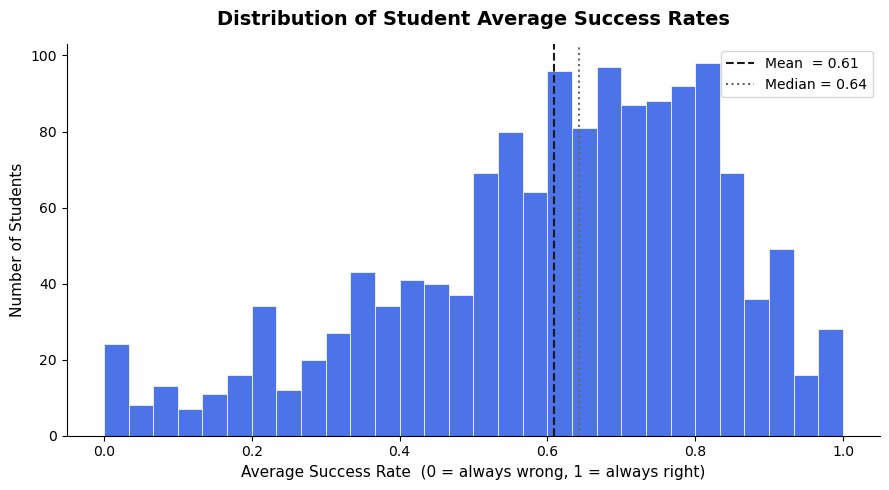

Caption: Each bar is the number of students with that average correct-answer rate.
A student near 1.0 answered almost everything correctly; near 0.0 almost nothing.


In [13]:
student_success = df.groupby("user_id")["correct"].mean()

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(student_success, bins=30, color="#2d5be3", edgecolor="white",
        linewidth=0.6, alpha=0.85)

ax.axvline(student_success.mean(), color="#1a1917", linestyle="--", linewidth=1.5,
           label=f"Mean  = {student_success.mean():.2f}")
ax.axvline(student_success.median(), color="#6b6760", linestyle=":", linewidth=1.5,
           label=f"Median = {student_success.median():.2f}")

ax.set_title("Distribution of Student Average Success Rates", fontsize=14,
             fontweight="bold", pad=14)
ax.set_xlabel("Average Success Rate  (0 = always wrong, 1 = always right)", fontsize=11)
ax.set_ylabel("Number of Students", fontsize=11)
ax.legend(fontsize=10)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "plot2_student_success_distribution.png"), dpi=150, bbox_inches="tight")
plt.show()

print("Caption: Each bar is the number of students with that average correct-answer rate.")
print("A student near 1.0 answered almost everything correctly; near 0.0 almost nothing.")

### Plot 3 — Difficulty vs Student Success Rate (Scatter)

Validates our difficulty formula. We expect a **clear negative correlation**: harder questions should have lower success rates. Each dot is one question, colored by topic.

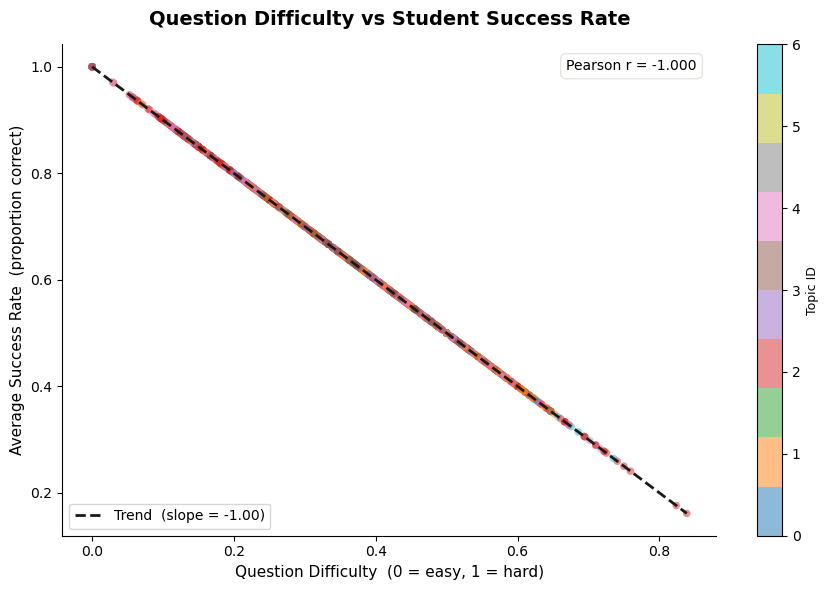

Caption: Each dot is one question. A strong negative correlation (r close to −1) confirms
that our difficulty formula correctly captures how hard students find each question.


In [14]:
q_stats = meta_df.copy()

n_topics = q_stats["topic_id"].nunique()

fig, ax = plt.subplots(figsize=(9, 6))

scatter = ax.scatter(
    q_stats["difficulty"],
    q_stats["success_rate"],
    c=q_stats["topic_id"],
    cmap="tab10", vmin=0, vmax=max(n_topics - 1, 1),
    alpha=0.5, s=30, edgecolors="none"
)

# Trend line
z  = np.polyfit(q_stats["difficulty"], q_stats["success_rate"], 1)
p  = np.poly1d(z)
xr = np.linspace(q_stats["difficulty"].min(), q_stats["difficulty"].max(), 200)
ax.plot(xr, p(xr), color="#1a1917", linewidth=2.0, linestyle="--",
        label=f"Trend  (slope = {z[0]:.2f})")

# Correlation
corr = q_stats["difficulty"].corr(q_stats["success_rate"])
ax.text(0.97, 0.97, f"Pearson r = {corr:.3f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#e8e4dc"))

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Topic ID", fontsize=9)
cbar.set_ticks(sorted(q_stats["topic_id"].unique()))

ax.set_title("Question Difficulty vs Student Success Rate", fontsize=14,
             fontweight="bold", pad=14)
ax.set_xlabel("Question Difficulty  (0 = easy, 1 = hard)", fontsize=11)
ax.set_ylabel("Average Success Rate  (proportion correct)", fontsize=11)
ax.legend(fontsize=10)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "plot3_difficulty_vs_success.png"), dpi=150, bbox_inches="tight")
plt.show()

print("Caption: Each dot is one question. A strong negative correlation (r close to −1) confirms")
print("that our difficulty formula correctly captures how hard students find each question.")

## **10 - Save Output Files**

In [15]:
SAVE_COLS = ["user_id", "problem_id", "correct", "topic_id", "skill_name",
             "difficulty", "response_time_norm", "hint_count", "attempt_count"]

# Keep only columns that exist
save_cols = [c for c in SAVE_COLS if c in train_df.columns]

train_df[save_cols].to_csv(os.path.join(OUTPUT_DIR, "train_data.csv"), index=False)
test_df[save_cols].to_csv(os.path.join(OUTPUT_DIR, "test_data.csv"),   index=False)
meta_df.to_csv(os.path.join(OUTPUT_DIR, "question_metadata.csv"),      index=False)

print("Files saved:")
print(f"    train_data.csv         -> {len(train_df):,} rows")
print(f"    test_data.csv          -> {len(test_df):,}  rows")
print(f"    question_metadata.csv  -> {len(meta_df):,}  questions")
print(f"     figures/               -> 3 PNG plots")

Files saved:
    train_data.csv         -> 41,700 rows
    test_data.csv          -> 10,645  rows
    question_metadata.csv  -> 958  questions
     figures/               -> 3 PNG plots


In [16]:
train_df[save_cols].head()

,user_id,problem_id,correct,topic_id,skill_name,difficulty,response_time_norm,hint_count,attempt_count
71512,53167,61100,1,2,Conversion of Fraction Decimals Percents,0.439189,0.159627,0,1
71513,53167,84787,1,2,Conversion of Fraction Decimals Percents,0.428571,0.040745,0,1
71514,53167,84744,1,2,Conversion of Fraction Decimals Percents,0.161290,-0.107056,0,1
71515,53167,84973,1,2,Conversion of Fraction Decimals Percents,0.150000,-0.112673,0,1
71517,53167,86048,0,2,Conversion of Fraction Decimals Percents,0.740741,-0.097907,2,3


## **11 - Final Summary**

In [17]:
print("=" * 55)
print(" Summary")
print("=" * 55)
print(f"  Total students   : {df['user_id'].nunique():,}")
print(f"  Total questions  : {df['problem_id'].nunique():,}")
print(f"  Total rows       : {len(df):,}")
print(f"  Topics kept ({TOPICS_TO_KEEP})  :")
for name, idx in topic_map.items():
    print(f"      {idx}  ->  {name}")
print(f"  Train students   : {train_df['user_id'].nunique():,}")
print(f"  Test students    : {test_df['user_id'].nunique():,}")
print("=" * 55)

 Summary
  Total students   : 1,417
  Total questions  : 958
  Total rows       : 52,345
  Topics kept (7)  :
      0  ->  Addition and Subtraction Fractions
      1  ->  Addition and Subtraction Integers
      2  ->  Conversion of Fraction Decimals Percents
      3  ->  Equation Solving More Than Two Steps
      4  ->  Equation Solving Two or Fewer Steps
      5  ->  Proportion
      6  ->  Subtraction Whole Numbers
  Train students   : 1,134
  Test students    : 283
